# Depression Detection — Exploratory Data Analysis

In [1]:
import sys
sys.path.append('../src')

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from data import load_twitter_dataset, preprocess
from features import linguistic_features

sns.set_theme(style='whitegrid')

## 1. Load & inspect

In [2]:
df_raw = load_twitter_dataset()
print(df_raw.shape)
df_raw.head()

README.md:   0%|          | 0.00/1.94k [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  134kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2000 [00:00<?, ? examples/s]

(2000, 2)


,text,label
0,"mood can be caused by infectious diseases, nu...",0
1,"With all of this unnessary family drama, I fe...",1
2,"I'm going to keep banging on about this, cos i...",0
3,Ugh. Woke up to the same acne covered face thi...,0
4,Portable Transparent Tobacco Rolling Machine ...,0


In [3]:
df = preprocess(df_raw)
df['label'].value_counts()

label
0    1187
1     783
Name: count, dtype: int64

## 2. Class balance

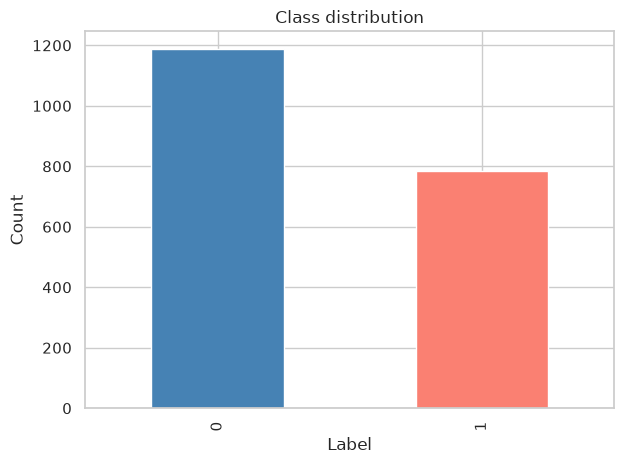

In [4]:
ax = df['label'].value_counts().plot(kind='bar', color=['steelblue', 'salmon'])
ax.set_title('Class distribution')
ax.set_xlabel('Label')
ax.set_ylabel('Count')
plt.tight_layout()

## 3. Text length distribution

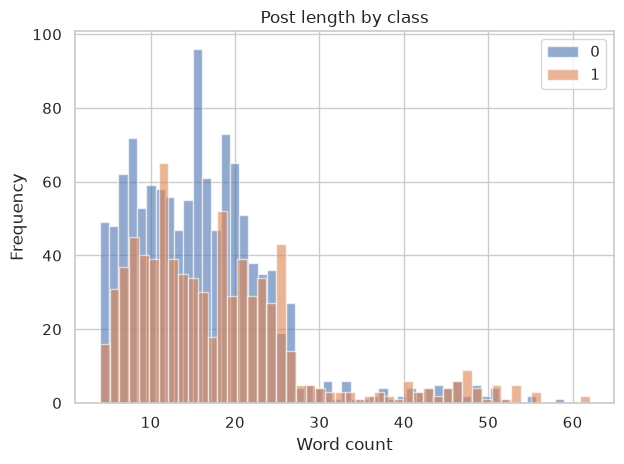

In [5]:
df['text_len'] = df['text'].str.split().str.len()
fig, ax = plt.subplots()
for label, grp in df.groupby('label'):
    grp['text_len'].clip(upper=300).plot.hist(bins=50, alpha=0.6, label=label, ax=ax)
ax.set_title('Post length by class')
ax.set_xlabel('Word count')
ax.legend()
plt.tight_layout()

## 4. Word clouds

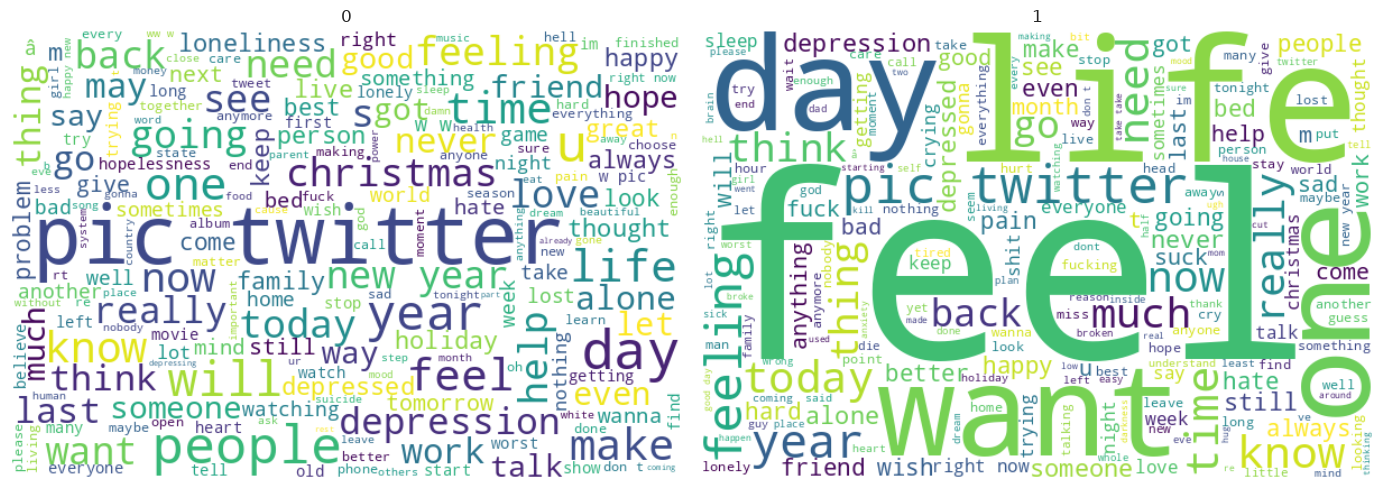

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, label in zip(axes, df['label'].unique()):
    corpus = ' '.join(df[df['label'] == label]['text'])
    wc = WordCloud(width=600, height=400, background_color='white').generate(corpus)
    ax.imshow(wc, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(label)
plt.tight_layout()

## 5. Linguistic features comparison

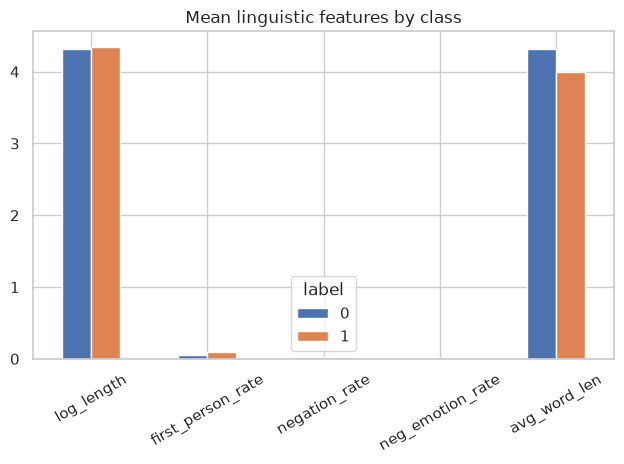

In [7]:
import numpy as np
feat_names = ['log_length', 'first_person_rate', 'negation_rate', 'neg_emotion_rate', 'avg_word_len']
feats = linguistic_features(df['text'].tolist())
feat_df = pd.DataFrame(feats, columns=feat_names)
feat_df['label'] = df['label'].values
feat_df.groupby('label')[feat_names].mean().T.plot(kind='bar')
plt.title('Mean linguistic features by class')
plt.xticks(rotation=30)
plt.tight_layout()

## 6. Baseline Model — Train & Evaluate

In [8]:
from scipy.sparse import hstack
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_curve, auc
from features import build_tfidf, linguistic_features
from model import build_baseline
from data import split_dataset

train, val, test = split_dataset(df)

# Build TF-IDF on train only
tfidf = build_tfidf(train['text'].tolist())

def make_features(split_df):
    tfidf_mat = tfidf.transform(split_df['text'].tolist())
    ling_mat  = linguistic_features(split_df['text'].tolist())
    return hstack([tfidf_mat, ling_mat])

X_train = make_features(train)
X_val   = make_features(val)
X_test  = make_features(test)

baseline = build_baseline()
baseline.fit(X_train, train['label'])
print("Trained. Evaluating on validation set...")
val_preds = baseline.predict(X_val)
print(classification_report(val['label'], val_preds))

Trained. Evaluating on validation set...
              precision    recall  f1-score   support

           0       0.75      0.69      0.72       178
           1       0.58      0.65      0.61       118

    accuracy                           0.67       296
   macro avg       0.66      0.67      0.66       296
weighted avg       0.68      0.67      0.67       296



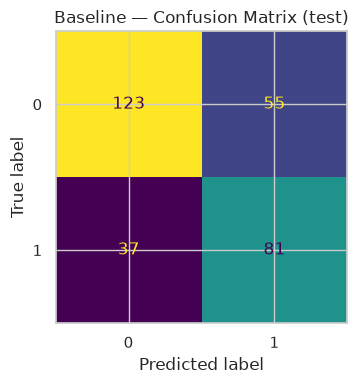

In [9]:
# Confusion matrix on test set
test_preds = baseline.predict(X_test)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(test['label'], test_preds, ax=ax, colorbar=False)
ax.set_title('Baseline — Confusion Matrix (test)')
plt.tight_layout()

/home/codespace/.local/lib/python3.14/site-packages/sklearn/metrics/_ranking.py:1364: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(


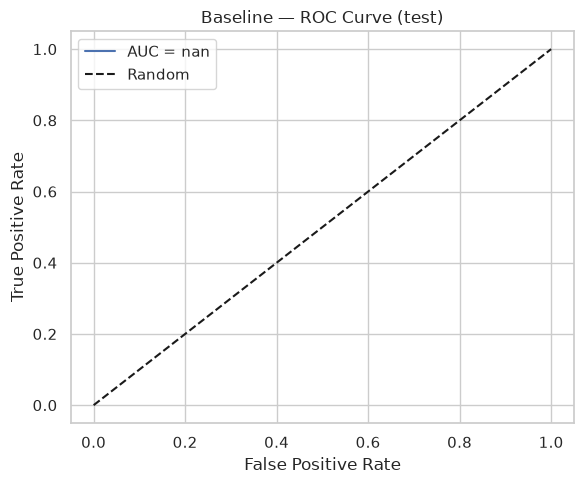

In [10]:
# ROC curve on test set
label_binarized = (test['label'] == 'depression').astype(int)
proba = baseline.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(label_binarized, proba)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
ax.plot([0, 1], [0, 1], 'k--', label='Random')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Baseline — ROC Curve (test)')
ax.legend()
plt.tight_layout()

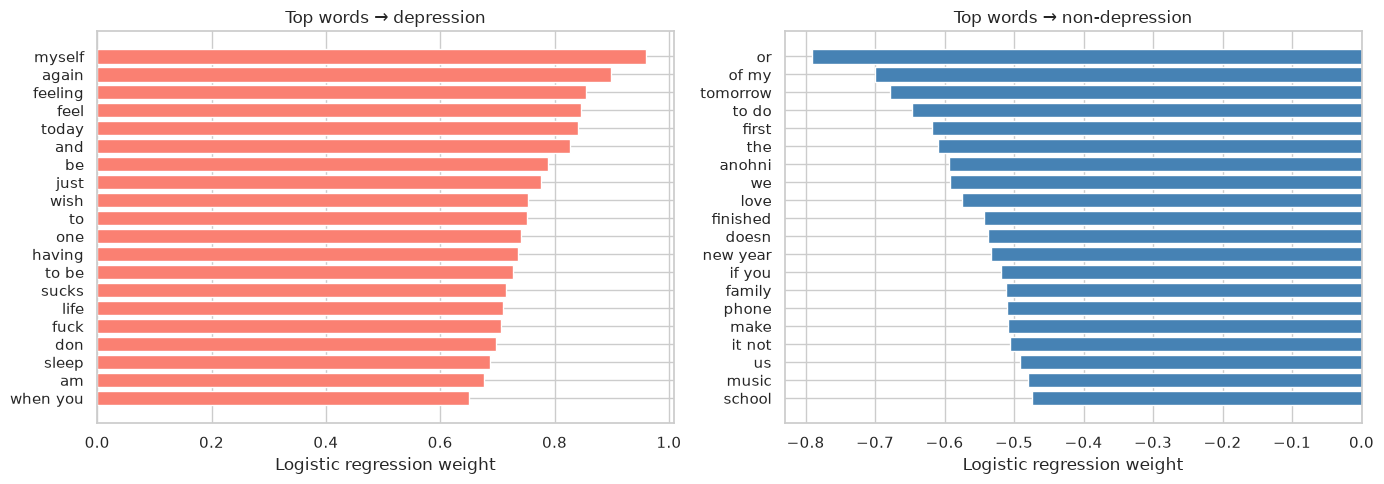

In [11]:
# Top predictive words (most positive/negative logistic regression weights)
import numpy as np

clf        = baseline.named_steps['clf']
vocab      = tfidf.get_feature_names_out()
n_ling     = 5  # linguistic features appended after tfidf
coefs      = clf.coef_[0][:len(vocab)]  # tfidf weights only

top_n = 20
top_pos_idx = np.argsort(coefs)[-top_n:][::-1]
top_neg_idx = np.argsort(coefs)[:top_n]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, indices, title, color in zip(
    axes,
    [top_pos_idx, top_neg_idx],
    ['Top words → depression', 'Top words → non-depression'],
    ['salmon', 'steelblue'],
):
    ax.barh([vocab[i] for i in indices][::-1], coefs[indices][::-1], color=color)
    ax.set_title(title)
    ax.set_xlabel('Logistic regression weight')
plt.tight_layout()

## 7. Transformer Model — Fine-tune & Evaluate

> **Runtime note:** fine-tuning BERT takes ~10–20 min on CPU. Run on a GPU (Google Colab or a local GPU) for faster results. Set `USE_TRANSFORMER = True` below to run this section.

In [21]:
USE_TRANSFORMER = True   # set to True to run fine-tuning
MODEL_NAME = "bert-base-uncased"  # or "mental/mental-bert-base-uncased"

In [28]:
if USE_TRANSFORMER:
    import torch
    from datasets import Dataset
    from transformers import TrainingArguments, Trainer
    import evaluate as hf_evaluate
    from model import TransformerConfig, load_transformer

    config = TransformerConfig(model_name=MODEL_NAME)
    tokenizer, bert_model = load_transformer(config)

    label2id = config.label2id

    def tokenize(batch):
        return tokenizer(batch['text'], truncation=True,
                         max_length=config.max_length, padding='max_length')

    def encode_labels(batch):
        def to_int(l):
            if isinstance(l, str):
                return label2id[l]
            return int(l)
        batch['labels'] = [to_int(l) for l in batch['label']]

    def make_hf_dataset(split_df):
        return (
            Dataset.from_pandas(split_df[['text', 'label']])
            .map(encode_labels, batched=True)
            .map(tokenize, batched=True)
            .remove_columns(['text', 'label'])
        )

    hf_train = make_hf_dataset(train)
    hf_val   = make_hf_dataset(val)
    hf_test  = make_hf_dataset(test)

    f1_metric = hf_evaluate.load('f1')

    def compute_metrics(eval_pred):
        logits, labels = eval_pred
        preds = np.argmax(logits, axis=-1)
        return f1_metric.compute(predictions=preds, references=labels, average='binary')

    training_args = TrainingArguments(
        output_dir='../checkpoints',
        num_train_epochs=config.epochs,
        per_device_train_batch_size=config.batch_size,
        per_device_eval_batch_size=config.batch_size,
        learning_rate=config.learning_rate,
        evaluation_strategy='epoch',
        save_strategy='epoch',
        load_best_model_at_end=True,
        metric_for_best_model='f1',
        report_to='none',
        logging_steps=50,
    )

    trainer = Trainer(
        model=bert_model,
        args=training_args,
        train_dataset=hf_train,
        eval_dataset=hf_val,
        compute_metrics=compute_metrics,
    )

    print(f"Fine-tuning {MODEL_NAME}...")
    trainer.train()
    print("Done.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/1378 [00:00<?, ? examples/s]

Map:   0%|          | 0/1378 [00:00<?, ? examples/s]

Map:   0%|          | 0/296 [00:00<?, ? examples/s]

Map:   0%|          | 0/296 [00:00<?, ? examples/s]

Map:   0%|          | 0/296 [00:00<?, ? examples/s]

Map:   0%|          | 0/296 [00:00<?, ? examples/s]

TypeError: TrainingArguments.__init__() got an unexpected keyword argument 'evaluation_strategy'

[1 0]


In [17]:
if USE_TRANSFORMER:
    # Evaluate on test set
    test_results = trainer.evaluate(hf_test)
    print("Test results:", test_results)

    # Confusion matrix
    test_preds_raw = trainer.predict(hf_test)
    bert_preds = np.argmax(test_preds_raw.predictions, axis=-1)
    bert_labels = test_preds_raw.label_ids
    id2label = config.id2label

    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(
        [id2label[l] for l in bert_labels],
        [id2label[p] for p in bert_preds],
        ax=ax, colorbar=False,
    )
    ax.set_title(f'{MODEL_NAME} — Confusion Matrix (test)')
    plt.tight_layout()

In [19]:
if USE_TRANSFORMER:
    # ROC curve
    import torch.nn.functional as F
    import torch

    logits_tensor = torch.tensor(test_preds_raw.predictions)
    proba_bert = F.softmax(logits_tensor, dim=-1)[:, 1].numpy()

    fpr_b, tpr_b, _ = roc_curve(bert_labels, proba_bert)
    auc_b = auc(fpr_b, tpr_b)

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.plot(fpr_b, tpr_b, label=f'{MODEL_NAME}  AUC = {auc_b:.3f}')
    ax.plot([0, 1], [0, 1], 'k--', label='Random')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title('Transformer — ROC Curve (test)')
    ax.legend()
    plt.tight_layout()